In [148]:
# Import plotly and pandas
import pandas as pd
import seaborn as sns

# Exploratory Data Analysis : inspect data types, check missing values , compute column statistics

In [149]:
fitness_data = pd.read_csv('synthetic_fitness_185_days.csv')
fitness_data.head()


,date,steps,weight,resting_heart_rate,sleep_hours,active_minutes,total_calories_burned,fat_burn_minutes,cardio_minutes,peak_minutes,workout_type,workout_duration,workout_calories,workout_avg_hr,workout_max_hr
0,2026-04-29,13926.0,74.9,60.0,6.6,81.0,2192.0,34.0,17.0,8.0,Running,26.0,220.0,171.0,196.0
1,2026-04-30,3888.0,74.9,68.0,6.9,38.0,1843.0,19.0,4.0,0.0,Yoga,41.0,114.0,87.0,120.0
2,2026-05-01,9436.0,75.0,62.0,7.7,82.0,2263.0,NaN,24.0,6.0,Running,39.0,387.0,139.0,157.0
3,2026-05-02,4421.0,74.9,69.0,8.6,67.0,1901.0,24.0,21.0,0.0,Strength Training,58.0,279.0,114.0,131.0
4,2026-05-03,10211.0,74.8,64.0,7.6,88.0,2033.0,32.0,23.0,2.0,Walking,56.0,195.0,98.0,124.0


In [150]:
fitness_data.info()
fitness_df = fitness_data.copy()
fitness_df['date'] = pd.to_datetime(fitness_df['date'],errors='coerce')

<class 'pandas.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   185 non-null    str    
 1   steps                  179 non-null    float64
 2   weight                 167 non-null    float64
 3   resting_heart_rate     173 non-null    float64
 4   sleep_hours            171 non-null    float64
 5   active_minutes         177 non-null    float64
 6   total_calories_burned  179 non-null    float64
 7   fat_burn_minutes       176 non-null    float64
 8   cardio_minutes         176 non-null    float64
 9   peak_minutes           176 non-null    float64
 10  workout_type           180 non-null    str    
 11  workout_duration       179 non-null    float64
 12  workout_calories       176 non-null    float64
 13  workout_avg_hr         169 non-null    float64
 14  workout_max_hr         167 non-null    float64
dtypes: float64(13), s

In [151]:
#Rows with missing values
missing_values = fitness_df[fitness_df.isnull().any(axis=1)]
missing_values

,date,steps,weight,resting_heart_rate,sleep_hours,active_minutes,total_calories_burned,fat_burn_minutes,cardio_minutes,peak_minutes,workout_type,workout_duration,workout_calories,workout_avg_hr,workout_max_hr
2,2026-05-01,9436.0,75.0,62.0,7.7,82.0,2263.0,NaN,24.0,6.0,Running,39.0,387.0,139.0,157.0
7,2026-05-06,4786.0,75.0,67.0,6.7,NaN,1600.0,14.0,1.0,0.0,Rest,0.0,0.0,0.0,0.0
8,2026-05-07,8968.0,74.8,67.0,NaN,NaN,2102.0,28.0,18.0,6.0,HIIT,26.0,256.0,158.0,186.0
13,2026-05-12,6310.0,NaN,65.0,6.8,48.0,1993.0,13.0,13.0,0.0,Walking,28.0,125.0,107.0,125.0
14,2026-05-13,NaN,75.5,66.0,6.6,78.0,1963.0,24.0,6.0,2.0,NaN,53.0,218.0,98.0,124.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
174,2026-10-20,8320.0,NaN,61.0,6.6,70.0,2112.0,33.0,16.0,1.0,Walking,50.0,182.0,99.0,116.0
177,2026-10-23,11685.0,NaN,63.0,7.2,69.0,2169.0,35.0,12.0,8.0,Running,31.0,NaN,141.0,NaN
180,2026-10-26,6029.0,74.6,58.0,7.1,28.0,1818.0,12.0,NaN,0.0,Rest,0.0,0.0,0.0,0.0
181,2026-10-27,8179.0,74.8,NaN,6.9,69.0,1782.0,35.0,4.0,1.0,Rest,0.0,0.0,0.0,0.0


In [152]:
summary_statistics = fitness_df.describe()
summary_statistics

,date,steps,weight,resting_heart_rate,sleep_hours,active_minutes,total_calories_burned,fat_burn_minutes,cardio_minutes,peak_minutes,workout_duration,workout_calories,workout_avg_hr,workout_max_hr
count,185,179.000000,167.000000,173.000000,171.000000,177.000000,179.000000,176.000000,176.000000,176.000000,179.000000,176.000000,169.000000,167.000000
mean,2026-07-30 00:00:00,8082.351955,75.101796,64.751445,7.342105,66.316384,1989.145251,26.272727,12.238636,2.590909,34.050279,205.335227,94.071006,111.233533
min,2026-04-29 00:00:00,2401.000000,73.400000,58.000000,3.100000,12.000000,1460.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2026-06-14 00:00:00,6299.000000,74.100000,63.000000,6.800000,52.000000,1860.500000,19.000000,6.000000,0.000000,20.500000,101.750000,87.000000,103.500000
50%,2026-07-30 00:00:00,7822.000000,75.100000,65.000000,7.200000,69.000000,2000.000000,26.500000,12.000000,1.000000,39.000000,220.000000,111.000000,135.000000
75%,2026-09-14 00:00:00,9778.500000,75.800000,67.000000,8.000000,80.000000,2127.500000,33.000000,18.250000,5.000000,50.000000,302.500000,137.000000,158.000000
max,2026-10-30 00:00:00,15741.000000,77.000000,72.000000,11.100000,123.000000,2507.000000,58.000000,38.000000,13.000000,82.000000,678.000000,171.000000,198.000000
std,NaN,2802.314143,1.030059,3.090037,0.962890,21.822148,209.052924,10.585410,8.487967,3.279848,21.842201,149.108728,56.627603,66.735131


In [153]:
fitness_df= fitness_df.rename(columns={'weight': 'body_weight_kg', 'workout_duration': 'workout_duration_minutes'})
fitness_df

,date,steps,body_weight_kg,resting_heart_rate,sleep_hours,active_minutes,total_calories_burned,fat_burn_minutes,cardio_minutes,peak_minutes,workout_type,workout_duration_minutes,workout_calories,workout_avg_hr,workout_max_hr
0,2026-04-29,13926.0,74.9,60.0,6.6,81.0,2192.0,34.0,17.0,8.0,Running,26.0,220.0,171.0,196.0
1,2026-04-30,3888.0,74.9,68.0,6.9,38.0,1843.0,19.0,4.0,0.0,Yoga,41.0,114.0,87.0,120.0
2,2026-05-01,9436.0,75.0,62.0,7.7,82.0,2263.0,NaN,24.0,6.0,Running,39.0,387.0,139.0,157.0
3,2026-05-02,4421.0,74.9,69.0,8.6,67.0,1901.0,24.0,21.0,0.0,Strength Training,58.0,279.0,114.0,131.0
4,2026-05-03,10211.0,74.8,64.0,7.6,88.0,2033.0,32.0,23.0,2.0,Walking,56.0,195.0,98.0,124.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180,2026-10-26,6029.0,74.6,58.0,7.1,28.0,1818.0,12.0,NaN,0.0,Rest,0.0,0.0,0.0,0.0
181,2026-10-27,8179.0,74.8,NaN,6.9,69.0,1782.0,35.0,4.0,1.0,Rest,0.0,0.0,0.0,0.0
182,2026-10-28,8365.0,74.8,64.0,6.7,68.0,1953.0,27.0,21.0,0.0,Yoga,35.0,102.0,85.0,107.0
183,2026-10-29,2911.0,74.8,68.0,7.5,23.0,1632.0,11.0,0.0,0.0,Rest,0.0,0.0,0.0,0.0


# Create useful new columns

In [154]:
#Feature engineering
fitness_df['body_weight_pounds'] = fitness_df['body_weight_kg'] * 2.20462
fitness_df['day_of_week'] = fitness_df['date'].dt.day_name()
fitness_df['is_weekend'] = fitness_df['day_of_week'].isin(['Saturday','Sunday'])
fitness_df['sleep_debt'] = fitness_df['sleep_hours'] - 7.5 
fitness_df['cum_sleep_dept'] = fitness_df['sleep_debt'].cumsum()
fitness_df['formatted_date'] = (
    fitness_df['date'].dt.strftime('%d %B %Y').str.lstrip('0')
)
fitness_df

,date,steps,body_weight_kg,resting_heart_rate,sleep_hours,active_minutes,total_calories_burned,fat_burn_minutes,cardio_minutes,peak_minutes,...,workout_duration_minutes,workout_calories,workout_avg_hr,workout_max_hr,body_weight_pounds,day_of_week,is_weekend,sleep_debt,cum_sleep_dept,formatted_date
0,2026-04-29,13926.0,74.9,60.0,6.6,81.0,2192.0,34.0,17.0,8.0,...,26.0,220.0,171.0,196.0,165.126038,Wednesday,False,-0.9,-0.9,29 April 2026
1,2026-04-30,3888.0,74.9,68.0,6.9,38.0,1843.0,19.0,4.0,0.0,...,41.0,114.0,87.0,120.0,165.126038,Thursday,False,-0.6,-1.5,30 April 2026
2,2026-05-01,9436.0,75.0,62.0,7.7,82.0,2263.0,NaN,24.0,6.0,...,39.0,387.0,139.0,157.0,165.346500,Friday,False,0.2,-1.3,1 May 2026
3,2026-05-02,4421.0,74.9,69.0,8.6,67.0,1901.0,24.0,21.0,0.0,...,58.0,279.0,114.0,131.0,165.126038,Saturday,True,1.1,-0.2,2 May 2026
4,2026-05-03,10211.0,74.8,64.0,7.6,88.0,2033.0,32.0,23.0,2.0,...,56.0,195.0,98.0,124.0,164.905576,Sunday,True,0.1,-0.1,3 May 2026
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180,2026-10-26,6029.0,74.6,58.0,7.1,28.0,1818.0,12.0,NaN,0.0,...,0.0,0.0,0.0,0.0,164.464652,Monday,False,-0.4,-25.1,26 October 2026
181,2026-10-27,8179.0,74.8,NaN,6.9,69.0,1782.0,35.0,4.0,1.0,...,0.0,0.0,0.0,0.0,164.905576,Tuesday,False,-0.6,-25.7,27 October 2026
182,2026-10-28,8365.0,74.8,64.0,6.7,68.0,1953.0,27.0,21.0,0.0,...,35.0,102.0,85.0,107.0,164.905576,Wednesday,False,-0.8,-26.5,28 October 2026
183,2026-10-29,2911.0,74.8,68.0,7.5,23.0,1632.0,11.0,0.0,0.0,...,0.0,0.0,0.0,0.0,164.905576,Thursday,False,0.0,-26.5,29 October 2026


# Visualizing trends across single variables

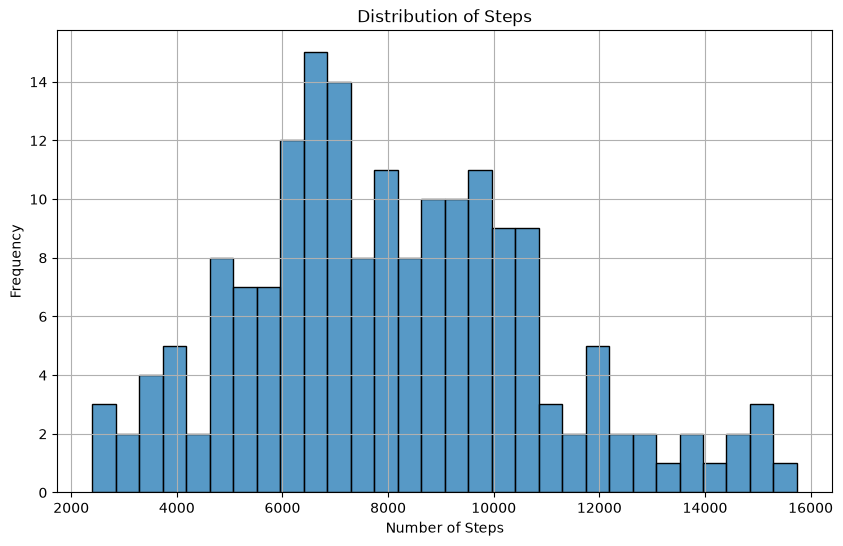

In [155]:
#plot distribution of number of steps 
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.histplot(data=fitness_df, x='steps', bins=30, edgecolor='black')
plt.title('Distribution of Steps')
plt.xlabel('Number of Steps')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

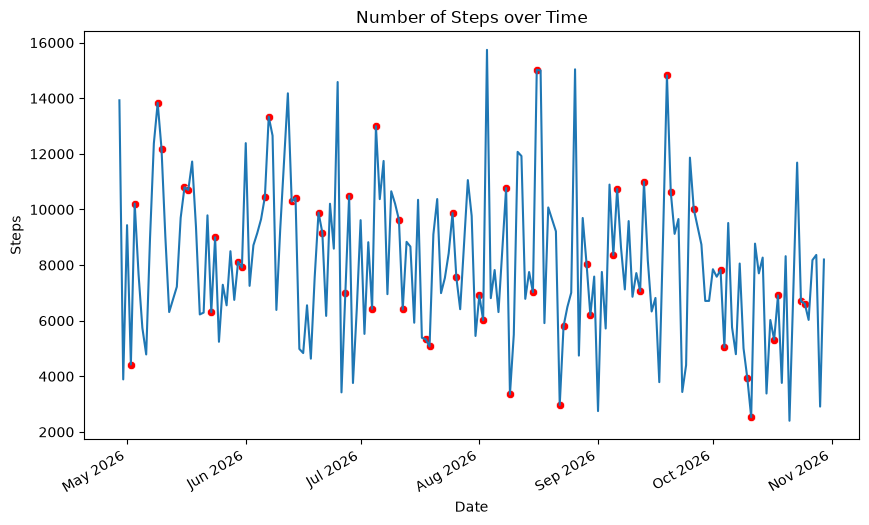

In [156]:
#plot number of steps over time
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

weekend_data = fitness_df.loc[fitness_df['is_weekend'].fillna(False).astype(bool)]

fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(
    data=fitness_df,
    x='date',
    y='steps',
    estimator=None,
    ax=ax
)

sns.scatterplot(
    data=weekend_data,
    x='date',
    y='steps',
    color='red',
    marker='o',
    ax=ax
)

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_xlabel('Date')
ax.set_ylabel('Steps')
ax.set_title('Number of Steps over Time')

fig.autofmt_xdate()
plt.show()


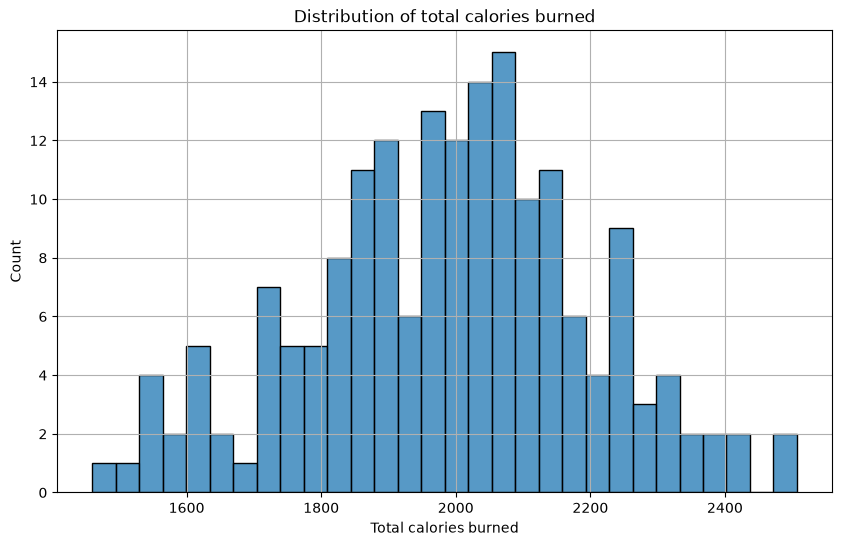

In [157]:
#plot distribution of total calories
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.histplot(data = fitness_df,x = 'total_calories_burned',bins=30,edgecolor='black')
plt.title('Distribution of total calories burned')
plt.xlabel('Total calories burned')
plt.ylabel('Count')
plt.grid(True)
plt.show()

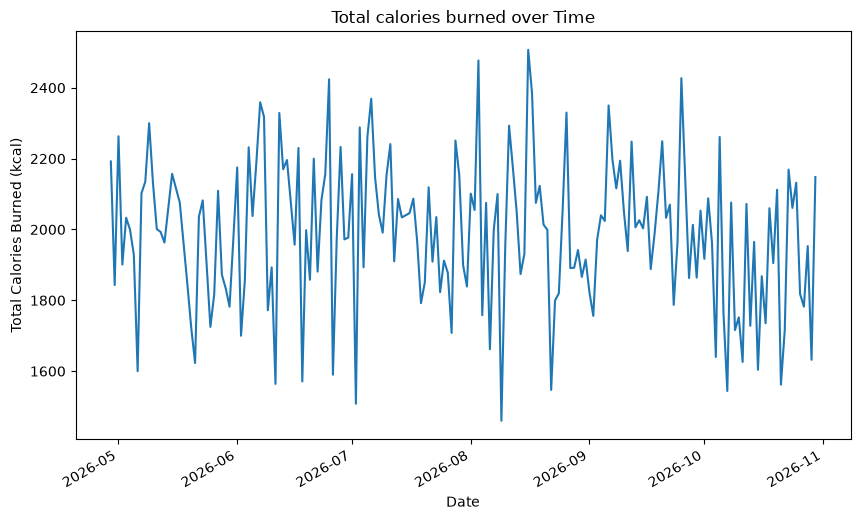

In [158]:
#plot total calories over time

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data = fitness_df, x= 'date', 
    y = 'total_calories_burned')

ax.set(xlabel='Date', ylabel='Total Calories Burned (kcal)', title='Total calories burned over Time')

fig.autofmt_xdate()
plt.show()

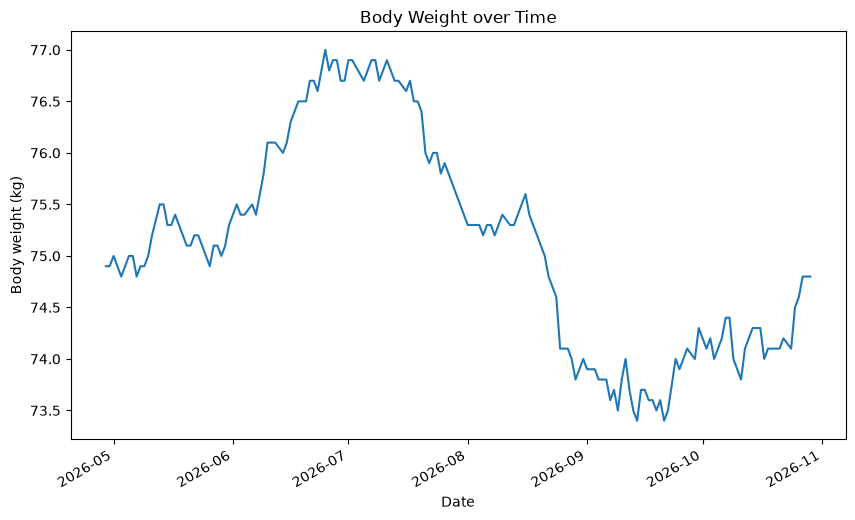

In [159]:
#plot body weight over time
fitness_df['date'] = pd.to_datetime(fitness_df['date'])

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=fitness_df, x='date', y='body_weight_kg', ax=ax)

ax.set(xlabel='Date', ylabel='Body weight (kg)', title='Body Weight over Time')
fig.autofmt_xdate()
plt.show()

# Visualizing trends across multiple variables

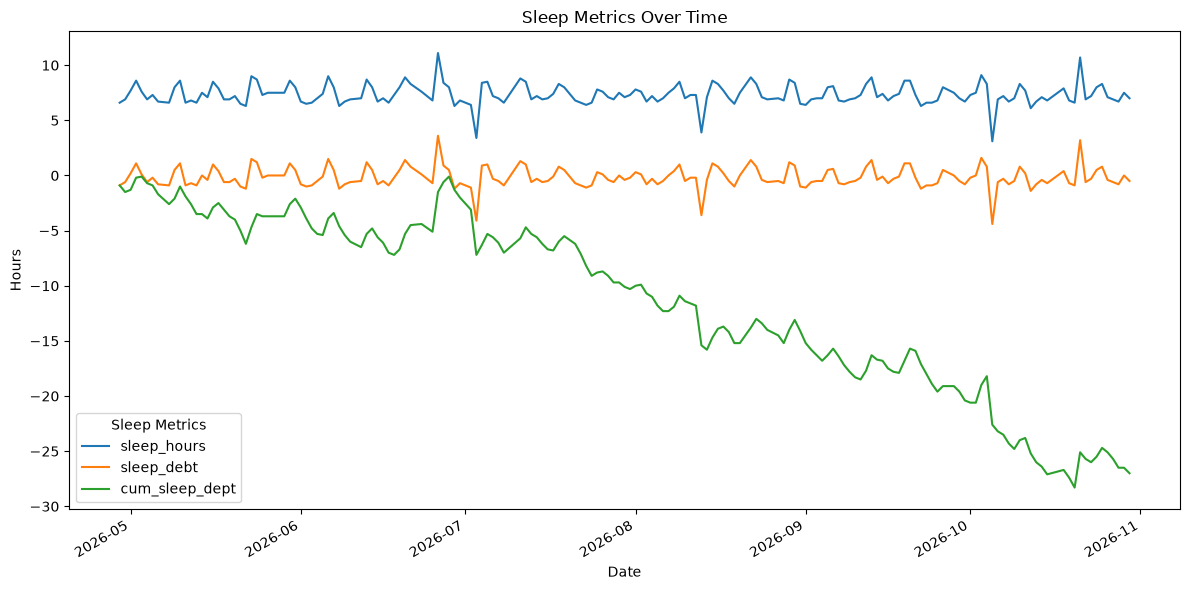

,date,Sleep Metrics,Hours
0,2026-04-29,sleep_hours,6.6
1,2026-04-30,sleep_hours,6.9
2,2026-05-01,sleep_hours,7.7
3,2026-05-02,sleep_hours,8.6
4,2026-05-03,sleep_hours,7.6
...,...,...,...
550,2026-10-26,cum_sleep_dept,-25.1
551,2026-10-27,cum_sleep_dept,-25.7
552,2026-10-28,cum_sleep_dept,-26.5
553,2026-10-29,cum_sleep_dept,-26.5


In [160]:
# Plot sleep metrics over time
sleep_df = fitness_df.melt(
    id_vars='date',
    value_vars=['sleep_hours', 'sleep_debt', 'cum_sleep_dept'],
    var_name='Sleep Metrics',
    value_name='Hours'
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=sleep_df,
    x='date',
    y='Hours',
    hue='Sleep Metrics',
    estimator=None,
    ax=ax
)

ax.set(title='Sleep Metrics Over Time', xlabel='Date', ylabel='Hours')

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

sleep_df

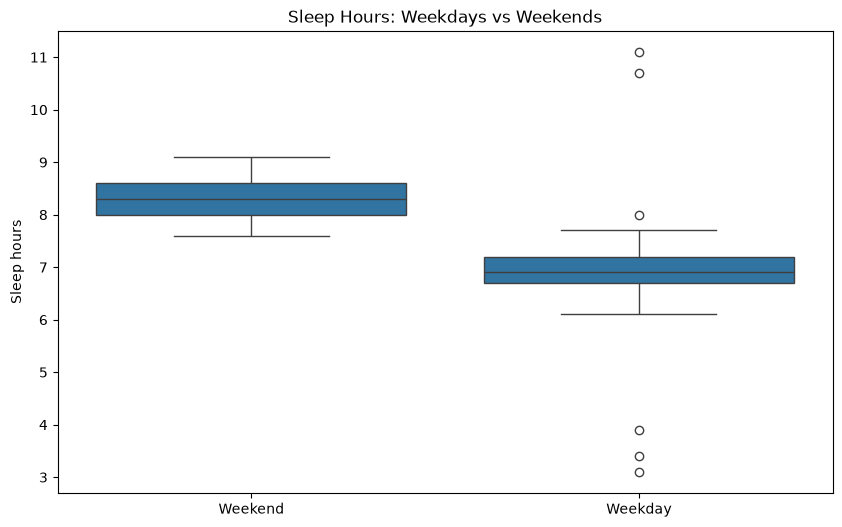

In [161]:
#Create a box plot for sleep hours comparing weekdays and weekends
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=fitness_df,
    x='is_weekend',
    y='sleep_hours',
    order=[True, False],
    ax=ax
)

ax.set_xticks([0, 1], labels=['Weekend', 'Weekday'])
ax.set(
    xlabel='',
    ylabel='Sleep hours',
    title='Sleep Hours: Weekdays vs Weekends'
)

plt.show()

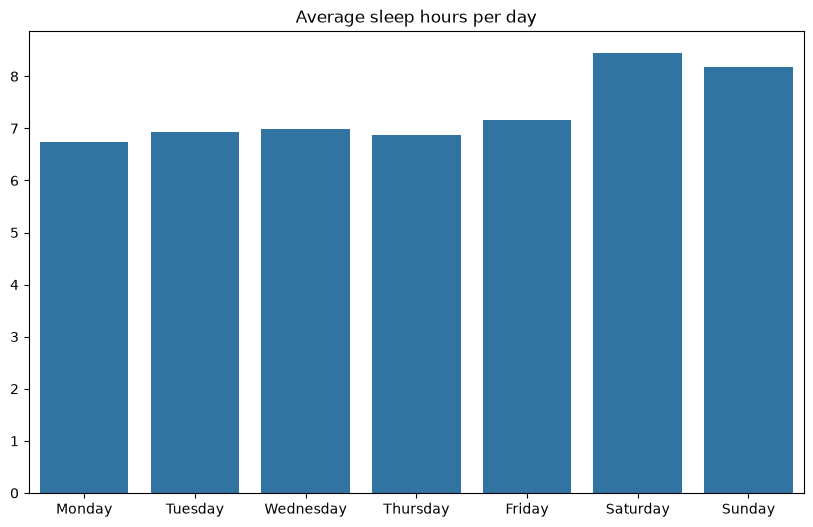

In [162]:
#Visualize average sleep hours by day
day_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]
avg_sleep_by_day = fitness_df.groupby('day_of_week').agg(
    mean_sleep_hours=('sleep_hours','mean')
).reset_index()

avg_sleep_by_day['day_of_week'] = pd.Categorical(
    avg_sleep_by_day['day_of_week'],
    categories=day_order,
    ordered=True
)
avg_sleep_by_day = avg_sleep_by_day.sort_values(by='day_of_week')

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=avg_sleep_by_day,
    x='day_of_week',
    y='mean_sleep_hours'
)

ax.set(
    xlabel='',
    ylabel='',
    title='Average sleep hours per day'
)
plt.show()


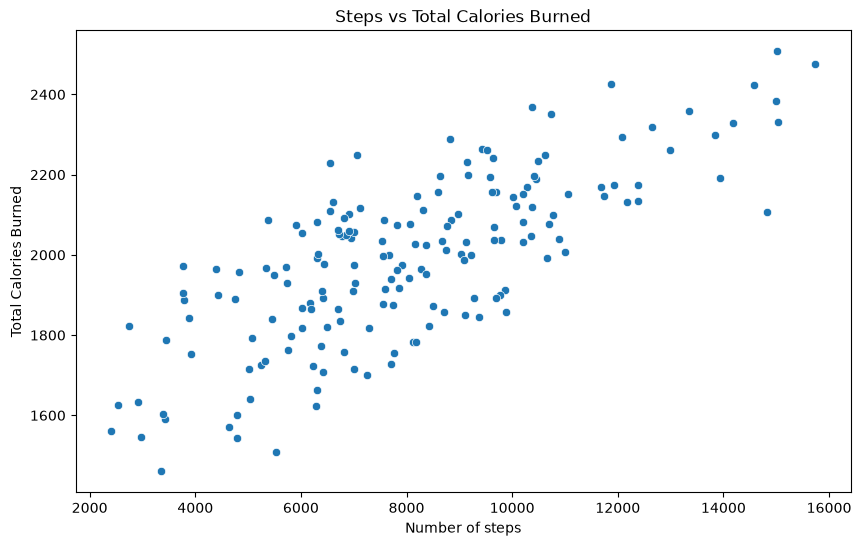

Correlation between calories burned and number of steps: 0.7547484263788959


In [163]:
#Visualize number of steps vs calories burned
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data = fitness_df, x='steps',y='total_calories_burned')
ax.set(
    xlabel='Number of steps',
    ylabel='Total Calories Burned',
    title='Steps vs Total Calories Burned'
)
plt.show()

print(f"Correlation between calories burned and number of steps: {fitness_df['total_calories_burned'].corr(fitness_df['steps'])}")

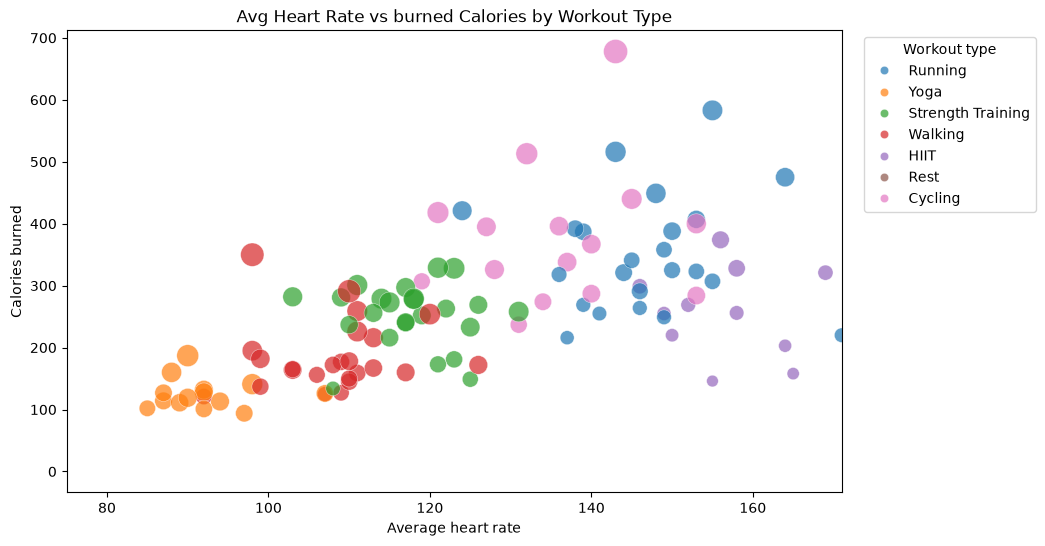

In [164]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=fitness_df,x="workout_avg_hr",y="workout_calories",hue="workout_type",size="workout_duration_minutes",sizes=(20, 300),
    alpha=0.7,ax=ax)

ax.set(
    xlabel='Average heart rate',
    ylabel='Calories burned',
    title='Avg Heart Rate vs burned Calories by Workout Type'
)

handles, labels = ax.get_legend_handles_labels()
size_index = labels.index('workout_duration_minutes')

ax.legend(
    handles[1:size_index],
    labels[1:size_index],
    title='Workout type',
    loc='upper left',
    bbox_to_anchor=(1.02, 1)
)
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1.02, 1))
plt.xlim(75,fitness_df['workout_avg_hr'].max())
plt.show()